# Raspagem de dados da Web + Análise de Sentimentos

**Disciplina:** T2ESOFT06NA · Ciência de Dados · 202623
**Loja escolhida:** [KaBuM!](https://www.kabum.com.br) · categoria *Headset Gamer*

Roteiro:
1. **Escolha do site** e verificação do `robots.txt` (T1)
2. **Raspagem** dos comentários com BeautifulSoup → `comentarios.csv` (T2)
3. **Rótulos e pré-processamento**: estrelas → Positivo/Negativo, stopwords, stemização RSLP (T3)
4. **Classificador Naive Bayes** (NLTK), acurácia e **matriz de confusão** (T4)
5. **Resultados e insights** (T5)

In [1]:
import os, re, json, string, subprocess, urllib.robotparser
from collections import Counter

import requests
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

import nltk
nltk.download('stopwords', quiet=True)
nltk.download('rslp', quiet=True)
from nltk.corpus import stopwords
from nltk.stem import RSLPStemmer
from nltk import FreqDist, NaiveBayesClassifier
from nltk.classify import accuracy as nltk_accuracy
from sklearn.model_selection import train_test_split

SEMENTE = 42
pd.set_option('display.max_colwidth', 120)

## 1. Escolha do site (T1)

Candidatos testados antes de escolher:

| Loja | Resultado |
|---|---|
| Buscapé (site do notebook de referência) | `robots.txt` bloqueia agentes de IA (`ClaudeBot`, `Claude-User`…) |
| Mercado Livre | idem |
| Magazine Luiza | 403 já no `robots.txt` |
| **KaBuM!** | `robots.txt` libera `/produto/` para `User-agent: *` → **escolhida** |

Abaixo, a verificação do `robots.txt` com `urllib.robotparser`, como o notebook de referência faz antes de coletar.

In [2]:
ROBOTS = 'https://www.kabum.com.br/robots.txt'
try:
    linhas = requests.get(ROBOTS, timeout=15).text.splitlines()
    rp = urllib.robotparser.RobotFileParser()
    rp.parse(linhas)
    print('/produto/727786/ permitido para "*"?', rp.can_fetch('*', 'https://www.kabum.com.br/produto/727786/'))
    # o robotparser do Python não entende curingas (*), então confiro também as regras na mão
    disallow = [l.split(':', 1)[1].strip() for l in linhas if l.lower().startswith('disallow')]
    print('Regras Disallow que mencionam "produto":', [d for d in disallow if 'produto' in d] or 'nenhuma')
except Exception as e:
    print('Sem acesso ao robots.txt agora:', e)

/produto/727786/ permitido para "*"? True
Regras Disallow que mencionam "produto": nenhuma


### Por que as páginas foram salvas do navegador (plano B)

A página de produto carrega os **comentários por JavaScript**, e a KaBuM **recusa requisições automatizadas**
(`requests` recebe HTTP 403). A célula abaixo mostra isso.

Por isso, seguindo o plano B (salvar a página com os comentários visíveis e raspar o arquivo salvo, como o notebook
de referência faz com páginas baixadas), cada produto foi aberto num navegador comum. As páginas de avaliações
foram percorridas com pausa de ~1 s entre elas, e o HTML de cada `<article>` de avaliação foi salvo (sem ícones e
imagens) em `dados/paginas/kabum_<id>.html`. Para garantir comentários negativos, além de "Todas as notas"
foram usados os filtros de 1 e 2 estrelas do próprio site.

In [3]:
try:
    r = requests.get('https://www.kabum.com.br/produto/727786/', timeout=15)
    print('HTTP', r.status_code, '| tem dados de avaliação no HTML?', 'aggregateRating' in r.text)
except Exception as e:
    print('Erro de rede:', e)

HTTP 403 | tem dados de avaliação no HTML? False


### Arquivos salvos

No Colab, a célula abaixo baixa os arquivos do repositório do trabalho (se a pasta `dados/` ainda não existir).

In [4]:
REPO = 'https://github.com/igorSeberino/web-scraping.git'
PASTA = 'dados/paginas'
if not os.path.isdir(PASTA):
    subprocess.run(['git', 'clone', '--depth', '1', REPO, 'web-scraping'], check=False)
    PASTA = 'web-scraping/dados/paginas'
arquivos = sorted(f for f in os.listdir(PASTA) if f.endswith('.html'))
arquivos

['kabum_102770.html',
 'kabum_109901.html',
 'kabum_128544.html',
 'kabum_461178.html',
 'kabum_596281.html',
 'kabum_596282.html',
 'kabum_612825.html',
 'kabum_727786.html']

Estrutura de uma avaliação no HTML salvo (inspecionada no navegador, como no notebook de referência):

```html
<article>
  <span>Autor</span>
  <span class="sr-only">Nota 5 de 5</span>
  <span>Avaliado em 07/06/2026</span>
  <h3>Título</h3>
  <p>Texto do comentário</p>
</article>
```

In [5]:
# T1: uma página raspada com BeautifulSoup
with open(os.path.join(PASTA, 'kabum_727786.html'), encoding='utf-8') as f:
    sopa = BeautifulSoup(f.read(), 'html.parser')

print('Produto:', sopa.find('h1').get_text(strip=True))
primeira = sopa.find('article')
print('Nota   :', primeira.find('span', class_='sr-only').get_text(strip=True))
print('Título :', primeira.find('h3').get_text(strip=True) if primeira.find('h3') else '')
print('Texto  :', primeira.find('p').get_text(strip=True) if primeira.find('p') else '')

Produto: Headset Gamer Redragon Zeus Lite P3, Drivers 53mm, PC PS5 Xbox, Preto - H510-LT
Nota   : Nota 1 de 5
Título : Microfone parou de funcionar
Texto  : Com apenas 4 meses de uso, o microfone parou de funcionar.

Infelizmente a garantia que é oferecida é só de 90 dias..

O Headset era bom e funcionava muito bem, porém o microfone ter parado de funcionar e não ter como consertar, foi uma decepção.


## 2. Raspagem dos comentários (T2)

In [6]:
def raspar_arquivo(caminho):
    with open(caminho, encoding='utf-8') as f:
        sopa = BeautifulSoup(f.read(), 'html.parser')
    produto = sopa.find('h1').get_text(strip=True)
    linhas = []
    for art in sopa.find_all('article'):
        spans = art.find_all('span', recursive=False)
        nota_txt = art.find('span', class_='sr-only').get_text(strip=True)    # "Nota 4 de 5"
        titulo = art.find('h3').get_text(' ', strip=True) if art.find('h3') else ''
        texto = art.find('p').get_text(' ', strip=True) if art.find('p') else ''
        data = next((s.get_text(strip=True) for s in spans if s.get_text().startswith('Avaliado em')), '')
        linhas.append({
            'produto': produto,
            'nota': int(re.search(r'Nota (\d)', nota_txt).group(1)),
            'comentario': (titulo + '. ' + texto).strip('. ') if texto else titulo,
            'autor': spans[0].get_text(strip=True) if spans else '',
            'data': data.replace('Avaliado em', '').strip(),
        })
    return linhas

registros = []
for arq in arquivos:
    registros += raspar_arquivo(os.path.join(PASTA, arq))

df_bruto = pd.DataFrame(registros)
print('Avaliações lidas (com repetidas):', len(df_bruto))
df_bruto.head()

Avaliações lidas (com repetidas): 347


,produto,nota,comentario,autor,data
0,"Headset Gamer Havit, Drivers 53mm, Microfone Plugável, 3.5mm, PC, PS4, XBOX ONE, Preto - HV-H2002D",1,fone horrível -1 mes de uso microfone não funciona. Produto ruim microfone não presta pelo preço não compensa,Anônimo,27/07/2026
1,"Headset Gamer Havit, Drivers 53mm, Microfone Plugável, 3.5mm, PC, PS4, XBOX ONE, Preto - HV-H2002D",1,"fone de ouvido muito baixo.. eu gostei de tudo no fone de ouvido, mas quando fui jogar ele era simplesmente baixíssi...",YASMIM,13/07/2026
2,"Headset Gamer Havit, Drivers 53mm, Microfone Plugável, 3.5mm, PC, PS4, XBOX ONE, Preto - HV-H2002D",1,"Produto parou de funcionar em apenas 5 meses.. O produto em si, não é ruim, o áudio do fone é bom e o microfone tamb...",Eduardo,04/06/2026
3,"Headset Gamer Havit, Drivers 53mm, Microfone Plugável, 3.5mm, PC, PS4, XBOX ONE, Preto - HV-H2002D",1,"O MIC não está funcionando, conectei 20 vezes, fiz os testes e nada. o áudio do fone de ouvido é top",Paulo,03/06/2026
4,"Headset Gamer Havit, Drivers 53mm, Microfone Plugável, 3.5mm, PC, PS4, XBOX ONE, Preto - HV-H2002D",1,Dura nada nem vale pena,Jefferson,13/04/2026


Limpeza: a mesma avaliação pode aparecer em "Todas as notas" e no filtro de 1 ou 2 estrelas, por isso removo as
repetidas (mesmo produto, autor, data, nota e texto). Também removo comentários vazios.

In [7]:
df = df_bruto.copy()
df['comentario'] = df['comentario'].str.replace(r'\s+', ' ', regex=True).str.strip()
df = df[df['comentario'] != '']
df = df.drop_duplicates(subset=['produto', 'autor', 'data', 'nota', 'comentario'])
df = df[['produto', 'nota', 'comentario']].drop_duplicates().reset_index(drop=True)

# nomes curtos para os gráficos
nome = df['produto'].str.replace('Headset Gamer ', '', regex=False).str.split(',').str[0].str.slice(0, 30)
modelo = df['produto'].str.rsplit(' - ', n=1).str[-1]
df['produto_curto'] = nome + ' (' + modelo + ')'

print('Avaliações após limpeza:', len(df))
print('Comentários vazios     :', df.comentario.str.strip().eq('').sum())
print('Linhas duplicadas      :', df.duplicated().sum())
# acento quebrado = UTF-8 lido como latin1 ("Ã§" no lugar de "ç"); "NÃO" em maiúsculas é legítimo
MOJIBAKE = r'Ã[\x80-\xbf]|Ã§|Ã£|Ã©|Ã¡|Ãª|Ã³|Ãº|Ã\xad'
print('Acento quebrado ("Ã§"…):', df.comentario.str.contains(MOJIBAKE, regex=True).sum())
print('  ("Ã" legítimo, ex. NÃO:', df.comentario.str.contains('Ã').sum(), 'linhas)')
df.nota.value_counts().sort_index()

Avaliações após limpeza: 327
Comentários vazios     : 0
Linhas duplicadas      : 0
Acento quebrado ("Ã§"…): 0
  ("Ã" legítimo, ex. NÃO: 4 linhas)


nota
1     82
2     55
3      6
4     12
5    172
Name: count, dtype: int64

In [8]:
df[['produto', 'nota', 'comentario']].to_csv('comentarios.csv', index=False, encoding='utf-8')
volta = pd.read_csv('comentarios.csv')
print('Linhas gravadas:', len(df), '| linhas lidas de volta:', len(volta))
df.groupby('produto_curto').nota.agg(['count', 'mean']).round(2).sort_values('count', ascending=False)

Linhas gravadas: 327 | linhas lidas de volta: 327


,count,mean
produto_curto,,
Havit (HV-H2002D),103,2.52
Redragon Zeus Lite P3 (H510-LT),47,3.66
Razer BlackShark V2 X (RZ04-03240100),42,3.88
Sem Fio Redragon Mira 7.1 (H868),39,3.82
Sem Fio Redragon Mira 7.1 (H868W),38,3.47
HyperX Cloud Stinger 2 Core (683L9AA),32,4.28
HP H320 (8AA13AAUUF),18,4.33
Infantil HyperX Cloud Mini (7G8F4AA),8,3.38


## 3. Rótulos e pré-processamento (T3)

Rótulo pelas estrelas (D3): **4–5 = Positivo**, **1–2 = Negativo**. Nota **3** fica fora do treino e só recebe
previsão no final.

Pré-processamento do material de referência: minúsculas, remoção de pontuação e de *stopwords* em português,
stemização **RSLP**.

In [9]:
def rotular(nota):
    if nota >= 4: return 'Positivo'
    if nota <= 2: return 'Negativo'
    return None

df['sentimento'] = df['nota'].apply(rotular)

PALAVRAS_DE_NEGACAO = {'não', 'nem', 'nunca', 'sem', 'mas', 'porém'}
STOP = set(stopwords.words('portuguese')) - PALAVRAS_DE_NEGACAO   # mantém negações: "não funciona" ≠ "funciona"
stemmer = RSLPStemmer()
TABELA = str.maketrans({p: ' ' for p in string.punctuation + '“”‘’…–—'})

def tokens_limpos(texto):
    texto = texto.lower().translate(TABELA)
    return [t for t in texto.split() if t not in STOP and not t.isdigit() and len(t) > 1]

def preprocessar(texto):
    return [stemmer.stem(t) for t in tokens_limpos(texto)]

df['tokens'] = df['comentario'].apply(tokens_limpos)
df['stems'] = df['comentario'].apply(preprocessar)

rotulados = df[df['sentimento'].notna()].copy()
print(rotulados['sentimento'].value_counts())
print('Notas no conjunto de treino/teste:', sorted(rotulados.nota.unique()))

sentimento
Positivo    184
Negativo    137
Name: count, dtype: int64
Notas no conjunto de treino/teste: [np.int64(1), np.int64(2), np.int64(4), np.int64(5)]


In [10]:
exemplos = pd.concat([rotulados[rotulados.sentimento == 'Negativo'].head(2), rotulados[rotulados.sentimento == 'Positivo'].head(1)])
for _, l in exemplos.iterrows():
    print(f"[{l.sentimento}] ANTES : {l.comentario[:150]}")
    print(f"{' ' * (len(l.sentimento) + 2)} DEPOIS: {l.stems[:20]}\n")

[Negativo] ANTES : fone horrível -1 mes de uso microfone não funciona. Produto ruim microfone não presta pelo preço não compensa
           DEPOIS: ['fon', 'horr', 'me', 'uso', 'microfon', 'não', 'func', 'produt', 'ruim', 'microfon', 'não', 'prest', 'preç', 'não', 'compens']

[Negativo] ANTES : fone de ouvido muito baixo.. eu gostei de tudo no fone de ouvido, mas quando fui jogar ele era simplesmente baixíssimo e eu nao escutava nada alem dos
           DEPOIS: ['fon', 'ouv', 'baix', 'gost', 'tud', 'fon', 'ouv', 'mas', 'jog', 'simples', 'baix', 'nao', 'escut', 'nad', 'alem', 'barulh', 'aqu', 'cas', 'experi', 'horri']

[Positivo] ANTES : Custo benefício
           DEPOIS: ['cust', 'benefíci']



## 4. Classificador Naive Bayes (T4)

Atributos: presença de cada radical (*bag of words*) dentre os 2.000 mais frequentes, como no material de referência.
Divisão **80/20 estratificada** pelo rótulo, semente 42.

In [11]:
todas_stems = FreqDist(s for lista in rotulados['stems'] for s in lista)
VOCAB = [w for w, _ in todas_stems.most_common(2000)]

def atributos(stems):
    presentes = set(stems)
    return {f'tem({w})': (w in presentes) for w in VOCAB}

treino, teste = train_test_split(rotulados, test_size=0.2, stratify=rotulados['sentimento'], random_state=SEMENTE)
conj_treino = [(atributos(s), y) for s, y in zip(treino['stems'], treino['sentimento'])]
conj_teste = [(atributos(s), y) for s, y in zip(teste['stems'], teste['sentimento'])]

classificador = NaiveBayesClassifier.train(conj_treino)
print(f'Treino: {len(treino)} | Teste: {len(teste)}')
print(f'Acurácia no teste: {nltk_accuracy(classificador, conj_teste):.3f}')

Treino: 256 | Teste: 65
Acurácia no teste: 0.862


Previsto  Positivo  Negativo
Real                        
Positivo        32         5
Negativo         4        24 

Positivo  precisão=0.89  revocação=0.86
Negativo  precisão=0.83  revocação=0.86


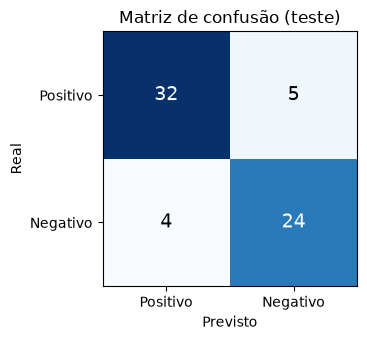

In [12]:
y_real = [y for _, y in conj_teste]
y_prev = [classificador.classify(x) for x, _ in conj_teste]
rot = ['Positivo', 'Negativo']
matriz = pd.crosstab(pd.Series(y_real, name='Real'), pd.Series(y_prev, name='Previsto')).reindex(index=rot, columns=rot, fill_value=0)
print(matriz, '\n')

for classe in rot:
    vp = matriz.loc[classe, classe]
    prec = vp / matriz[classe].sum() if matriz[classe].sum() else 0
    rec = vp / matriz.loc[classe].sum() if matriz.loc[classe].sum() else 0
    print(f'{classe:9s} precisão={prec:.2f}  revocação={rec:.2f}')

fig, ax = plt.subplots(figsize=(4, 3.5))
ax.imshow(matriz.values, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, matriz.values[i, j], ha='center', va='center', fontsize=14,
                color='white' if matriz.values[i, j] > matriz.values.max() / 2 else 'black')
ax.set_xticks([0, 1], rot); ax.set_yticks([0, 1], rot)
ax.set_xlabel('Previsto'); ax.set_ylabel('Real'); ax.set_title('Matriz de confusão (teste)')
plt.tight_layout(); plt.show()

In [13]:
classificador.show_most_informative_features(10)

Most Informative Features
               tem(func) = True           Negati : Positi =     16.6 : 1.0
            tem(funcion) = True           Negati : Positi =     14.8 : 1.0
            tem(problem) = True           Negati : Positi =     13.9 : 1.0
              tem(porém) = True           Negati : Positi =     12.1 : 1.0
                tem(par) = True           Negati : Positi =     11.0 : 1.0
               tem(baix) = True           Negati : Positi =      9.4 : 1.0
                tem(dur) = True           Negati : Positi =      7.6 : 1.0
                tem(sup) = True           Positi : Negati =      7.2 : 1.0
             tem(defeit) = True           Negati : Positi =      6.7 : 1.0
                tem(top) = True           Positi : Negati =      6.7 : 1.0


In [14]:
df['sentimento_previsto'] = [classificador.classify(atributos(s)) for s in df['stems']]
print('Previsões vazias:', df['sentimento_previsto'].isna().sum())
print('\nComentários de nota 3 (fora do treino) e o sentimento previsto:')
df[df.nota == 3][['produto_curto', 'comentario', 'sentimento_previsto']]

Previsões vazias: 0

Comentários de nota 3 (fora do treino) e o sentimento previsto:


,produto_curto,comentario,sentimento_previsto
110,HP H320 (8AA13AAUUF),"ÁUDIO EXTREMAMENTE BAIXO. Áudio muito baixo,existe melhores na mesma faixa de preço,design bonito",Positivo
184,HyperX Cloud Stinger 2 Core (683L9AA),ACEITAVEL. BOM PRODUTO MAS PODE DAR PROBLEMAS FUTURAMENTE,Positivo
264,Sem Fio Redragon Mira 7.1 (H868W),"Bom. O o Headset é bom, só o microfone dele (não sei se é só o meu) fica muito baixo o áudio ou não detecta a minha ...",Positivo
266,Sem Fio Redragon Mira 7.1 (H868W),"Ótimo produto!. No geral, veio tudo certinho, tudo muito bem embalado, e lacrado. Mas durante os testes notei que um...",Negativo
269,Sem Fio Redragon Mira 7.1 (H868W),"Bonito porém de qualidade fraca. O fone tem um design muito bonito e chama atenção pelo acabamento. Porém, a qualida...",Positivo
273,Infantil HyperX Cloud Mini (7G8F4AA),"Mais ou menos. Fone pequeno, mas o áudio e o microfone são excelentes",Positivo


## 5. Resultados e insights (T5)

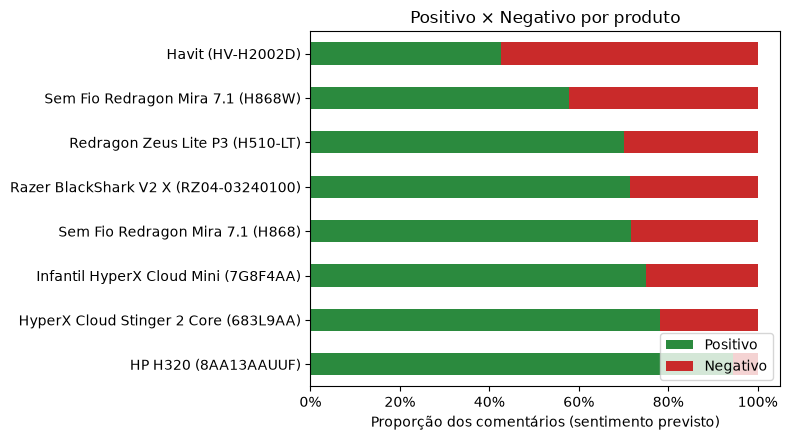

sentimento_previsto,Positivo,Negativo
produto_curto,,
HP H320 (8AA13AAUUF),94.4,5.6
HyperX Cloud Stinger 2 Core (683L9AA),78.1,21.9
Infantil HyperX Cloud Mini (7G8F4AA),75.0,25.0
Sem Fio Redragon Mira 7.1 (H868),71.8,28.2
Razer BlackShark V2 X (RZ04-03240100),71.4,28.6
Redragon Zeus Lite P3 (H510-LT),70.2,29.8
Sem Fio Redragon Mira 7.1 (H868W),57.9,42.1
Havit (HV-H2002D),42.7,57.3


In [15]:
prop = (df.groupby('produto_curto')['sentimento_previsto'].value_counts(normalize=True)
          .unstack(fill_value=0).reindex(columns=['Positivo', 'Negativo'], fill_value=0)
          .sort_values('Negativo'))
ax = prop.plot(kind='barh', stacked=True, color=['#2b8a3e', '#c92a2a'], figsize=(8, 4.5))
ax.set_xlabel('Proporção dos comentários (sentimento previsto)'); ax.set_ylabel('')
ax.set_title('Positivo × Negativo por produto'); ax.legend(loc='lower right')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
plt.tight_layout(); plt.show()
(prop * 100).round(1)

Atenção: a proporção de negativos aqui **não** é a proporção real da loja, porque a coleta usou os filtros de
1 e 2 estrelas para ter exemplos negativos suficientes (ver Limitações). Ela serve para comparar produtos entre si.

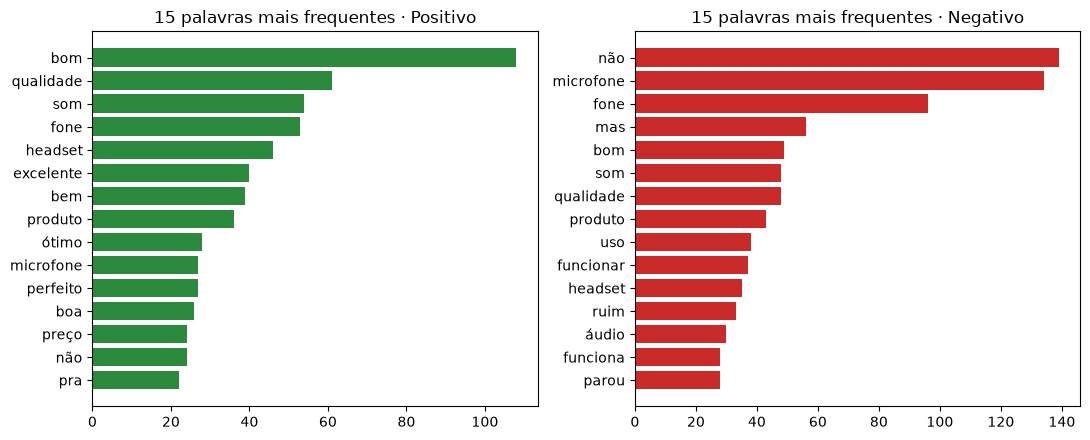

,Positivo,Negativo
0,bom (108),não (139)
1,qualidade (61),microfone (134)
2,som (54),fone (96)
3,fone (53),mas (56)
4,headset (46),bom (49)
5,excelente (40),som (48)
6,bem (39),qualidade (48)
7,produto (36),produto (43)
8,ótimo (28),uso (38)
9,microfone (27),funcionar (37)


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
top = {}
for ax, classe, cor in zip(axes, ['Positivo', 'Negativo'], ['#2b8a3e', '#c92a2a']):
    fd = FreqDist(t for lista in rotulados[rotulados.sentimento == classe]['tokens'] for t in lista)
    top[classe] = fd.most_common(15)
    palavras, freq = zip(*top[classe])
    ax.barh(palavras[::-1], freq[::-1], color=cor)
    ax.set_title(f'15 palavras mais frequentes · {classe}')
plt.tight_layout(); plt.show()
pd.DataFrame({k: [f'{w} ({n})' for w, n in v] for k, v in top.items()})

In [17]:
# Assuntos que mais aparecem nos comentários negativos
neg = rotulados[rotulados.sentimento == 'Negativo']
temas = {
    'microfone': r'micro|mic\b', 'som / áudio': r'\bsom\b|áudio|audio|chiado|chiand',
    'defeito / parou': r'defeit|parou|quebr|estrag|não funcion|nao funcion',
    'conexão / bateria': r'bateria|bluetooth|conex|desconect|carreg|sem fio|wireless',
    'conforto / tamanho': r'confort|apert|dói|doi\b|orelha|cabeça',
    'entrega / atendimento': r'entreg|troca|devolu|suporte|atendimento|garantia',
}
contagem = {t: neg['comentario'].str.lower().str.contains(p, regex=True).mean() for t, p in temas.items()}
(pd.Series(contagem).sort_values(ascending=False) * 100).round(1).rename('% dos comentários negativos')

microfone                56.9
defeito / parou          44.5
som / áudio              42.3
conforto / tamanho       21.2
conexão / bateria         9.5
entrega / atendimento     8.8
Name: % dos comentários negativos, dtype: float64

### Insights

Os números citam as células de código pela ordem de execução ("Reiniciar e executar tudo").

1. **O classificador acerta 86,2% no teste, com erros equilibrados** (células [11] e [12]). Dos 37 positivos, 32 foram
   acertados; dos 28 negativos, 24. Precisão e revocação ficam entre 0,83 e 0,89 nas duas classes, então o modelo não
   está só "chutando Positivo", o que é o risco com classes desbalanceadas.
2. **O microfone é a principal reclamação.** Aparece em **56,9%** dos comentários negativos (célula [17]) e é a 2ª
   palavra mais frequente da classe Negativo (134 ocorrências, contra 27 nos positivos, célula [16]).
3. **Durabilidade pesa mais que qualidade inicial.** 44,5% dos negativos falam de defeito ou de algo que "parou"
   (célula [17]). As palavras mais informativas do modelo são quase todas desse tema: `func`/`funcion` (16,6 : 1),
   `problem`, `par` (parou), `dur` (durou), `defeit` (célula [13]). Muitos negativos elogiam o som e reclamam que o
   produto quebrou meses depois.
4. **Os positivos falam de custo-benefício e som:** `bom`, `qualidade`, `som`, `excelente`, `preço` estão no top 15
   (célula [16]). "Bom" é tão comum que aparece também entre os negativos ("é bom, mas…"); por isso `porém` virou um
   forte indicador de Negativo (12,1 : 1, célula [13]).
5. **Comentários mistos enganam o modelo.** Das 6 avaliações de nota 3, 5 foram previstas como Positivo (célula [14]),
   inclusive "Áudio extremamente baixo…" e "Bonito porém de qualidade fraca". O modelo aprendeu bem os extremos (1–2 e
   4–5), mas tende a Positivo quando o texto mistura elogio e crítica.
6. **Entre os produtos** (célula [15]), o HP H320 tem a maior proporção positiva (94%), e o Havit HV-H2002D a menor
   (57% negativos). Mas o Havit tem média **4,8 no site** com 3.476 avaliações, contra 2,52 na nossa base (célula [8]):
   a diferença vem da coleta, que priorizou os filtros de 1 e 2 estrelas nesse produto. É um bom exemplo de como o
   modo de amostragem muda a conclusão.

### Limitações

- **Classes desbalanceadas e amostra enviesada.** Na loja, a grande maioria das avaliações é 4–5 estrelas. Para ter
  negativos suficientes, a coleta usou os filtros de 1 e 2 estrelas, então a proporção de negativos na base é bem maior
  que a real. A acurácia também precisa ser lida junto com a matriz de confusão, e não sozinha.
- **Estrela ≠ texto.** O rótulo vem da nota, não do texto. Há comentários de 5 estrelas que reclamam de algo e de
  1 estrela que elogiam o produto mas reclamam da entrega. O classificador aprende com esses rótulos "ruidosos".
- **Base pequena.** Com algumas centenas de comentários curtos, poucas palavras decidem a previsão. Uma palavra
  rara pode pesar demais (veja as palavras mais informativas).
- **Uma categoria só.** Todos os produtos são headsets, então as conclusões não valem para outras categorias.
- **Coleta pelo navegador.** O site bloqueia `requests` (HTTP 403). As páginas foram salvas do navegador e raspadas
  localmente; refazer a coleta exige repetir esse passo.